# Experiment 19: PCA and Explained Variance Analysis

A face-recognition attendance system wants fewer pixel features without losing most information. We generate small synthetic grayscale face-like patterns, implement PCA using covariance eigendecomposition, verify against scikit-learn and reconstruct images at several component counts.

**Tools:** NumPy, Scikit-learn, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Implement PCA from covariance and eigen-decomposition.  2. Compare projections with Scikit-learn PCA.  3. Plot scree and cumulative variance; find components needed for 95%.  4. Display principal components as eigenfaces.  5. Reconstruct images with 10, 50 and 100 components.

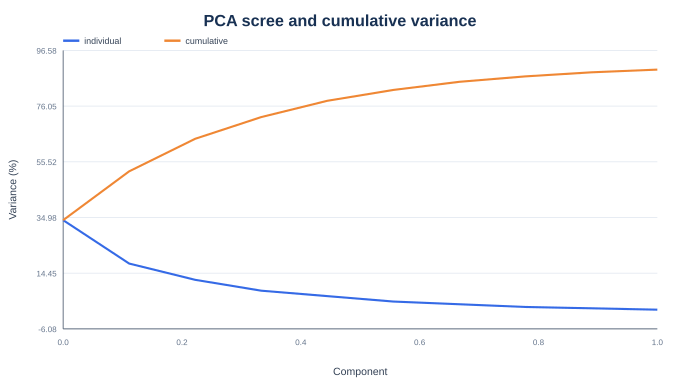

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

rng=np.random.default_rng(19)
h=w=16;n=320
yy,xx=np.mgrid[0:h,0:w]
images=[]
for i in range(n):
    cx=rng.normal(8,1.8);cy=rng.normal(8,1.8);radius=rng.uniform(3,6)
    face=np.exp(-((xx-cx)**2+(yy-cy)**2)/(2*radius**2))
    eyes=np.exp(-((xx-(cx-2))**2+(yy-(cy-1))**2)/1.4)+np.exp(-((xx-(cx+2))**2+(yy-(cy-1))**2)/1.4)
    smile=np.exp(-((yy-(cy+2))**2)/1.2)*np.exp(-((xx-cx)**2)/8)
    images.append(np.clip(.25+.45*face+.2*eyes+.15*smile+rng.normal(0,.04,(h,w)),0,1))
X=np.array(images).reshape(n,-1)
mu=X.mean(axis=0);Xc=X-mu
cov=np.cov(Xc,rowvar=False)
values,vectors=np.linalg.eigh(cov);order=np.argsort(values)[::-1]
values=values[order];components=vectors[:,order].T
variance=values/values.sum();cumulative=np.cumsum(variance)
k95=np.searchsorted(cumulative,.95)+1
print(f"Components needed for 95% variance: {k95}")
pca=PCA(n_components=100,svd_solver="full").fit(X)
projection=Xc@components[:10].T
sk_projection=pca.transform(X)[:,:10]
print("Absolute correlation between first manual and sklearn PC score:",
      round(abs(np.corrcoef(projection[:,0],sk_projection[:,0])[0,1]),6))

fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(np.arange(1,101),variance[:100],"o-",ms=3);axes[0].set(title="Scree plot",xlabel="Component",ylabel="Variance fraction")
axes[1].plot(np.arange(1,101),cumulative[:100]);axes[1].axhline(.95,color="r",ls="--")
axes[1].axvline(k95,color="r",ls=":");axes[1].set(title="Cumulative explained variance",xlabel="Components",ylabel="Cumulative fraction")
for ax in axes:ax.grid(alpha=.2)
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,5,figsize=(10,2))
for i,ax in enumerate(axes):ax.imshow(components[i].reshape(h,w),cmap="gray");ax.set_title(f"PC{i+1}");ax.axis("off")
plt.suptitle("Top eigenfaces / principal components");plt.show()

fig,axes=plt.subplots(3,4,figsize=(9,6))
for row,k in enumerate([10,50,100]):
    k=min(k,X.shape[1])
    Z=Xc@components[:k].T
    recon=Z@components[:k]+mu
    for col,img in enumerate([X[row].reshape(h,w),recon[row].reshape(h,w),X[row+1].reshape(h,w),recon[row+1].reshape(h,w)]):
        axes[row,col].imshow(img,cmap="gray",vmin=0,vmax=1);axes[row,col].axis("off")
        if row==0:axes[row,col].set_title(["original","reconstruction","original","reconstruction"][col])
    axes[row,0].set_ylabel(f"k={k}")
plt.tight_layout();plt.show()